<a href="https://colab.research.google.com/github/DinaKSari/244107020072_PEMBELAJARAN_MESIN/blob/main/PBL_TG14_244107020072_DINA_KUMALA_SARI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum 1
Klasifikasi
- awal pertumbuhan
- tengah pertumbuhan
- akhir pertumbuhan

In [5]:
import pandas as pd
import numpy as np

df = pd.read_csv('lettuce.csv', encoding='latin1')
df.head()


,Plant_ID,Date,Temperature (°C),Humidity (%),TDS Value (ppm),pH Level,Growth Days,Temperature (F),Humidity
0,1,8/3/2023,33.4,53,582,6.4,1,92.12,0.53
1,1,8/4/2023,33.5,53,451,6.1,2,92.30,0.53
2,1,8/5/2023,33.4,59,678,6.4,3,92.12,0.59
3,1,8/6/2023,33.4,68,420,6.4,4,92.12,0.68
4,1,8/7/2023,33.4,74,637,6.5,5,92.12,0.74


## Langkah 1 - Import Library

In [6]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from tensorflow.keras.utils import to_categorical

## Langkah 2 - Pra Pengolahan Data

### Langkah 2.1. Pra Pengolahan Data Training

In [7]:
# Tentukan fitur dan target dari df (lettuce dataset)
# Kita akan menggunakan fitur numerik seperti: Temperature, Humidity, TDS Value, pH Level
fitur_kolom = ['Temperature (°C)', 'Humidity (%)', 'TDS Value (ppm)', 'pH Level']

# Memastikan label klasifikasi telah dibuat di df
def kelompokkan_pertumbuhan(hari):
    if hari <= 15:
        return 'Awal'
    elif hari <= 30:
        return 'Tengah'
    else:
        return 'Akhir'

df['Kategori_Pertumbuhan'] = df['Growth Days'].apply(kelompokkan_pertumbuhan)

X = df[fitur_kolom].values
y = df['Kategori_Pertumbuhan'].values

# Label Encoding untuk target (Awal, Tengah, Akhir)
le = LabelEncoder()
y_encoded = le.fit_transform(y)
y_categorical = to_categorical(y_encoded)

# Split data menjadi Training (80%) dan Testing (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y_categorical, test_size=0.2, random_state=42)

# Normalisasi skala fitur
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Ukuran Data Training:", X_train.shape)
print("Ukuran Data Testing:", X_test.shape)
print("Urutan Kelas:", le.classes_)

Ukuran Data Training: (2535, 4)
Ukuran Data Testing: (634, 4)
Urutan Kelas: ['Akhir' 'Awal' 'Tengah']


### Langkah 2.2. Pra Pengolahan Data Testing

In [8]:
# Menampilkan informasi kelas target setelah encoding
for i, kelas in enumerate(le.classes_):
    print(f"Indeks {i}: {kelas}")

Indeks 0: Akhir
Indeks 1: Awal
Indeks 2: Tengah


# Langkah 3 - Pembuatan Model CNN

## Langkah 3.1.  - Inisiasi Model CNN

In [9]:
# Inisialisasi Model Sequential Jaringan Saraf Tiruan (ANN)
model_lettuce = Sequential()

## Langkah 3.2. - Pembuatan Layer Konvolusi 1

In [10]:
# Tambahkan Input Layer dan Hidden Layer Pertama
model_lettuce.add(Dense(units=32, activation='relu', input_shape=(X_train.shape[1],)))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


## Langkah 3.3 - Pembuatan Layer Pooling 1

cnn.add(tf.keras.layers.MaxPool2D(pool_size=2, strides=2))

## Langkah 3.4 - Pembuatan Layer Konvolusi 2 dan Pooling 2

In [11]:
# Tambahkan Hidden Layer Kedua
model_lettuce.add(Dense(units=16, activation='relu'))
model_lettuce.add(Dropout(0.2))

## Langkah 3.5 - Flattening



In [13]:
# Langkah Flattening dilewati karena data lettuce adalah data tabular terstruktur,
# bukan data citra 2D/3D yang perlu diratakan.

## Langkah 3.6 - Fully Connected Layer 1 (Input)



In [15]:
# Menambahkan Fully Connected Layer ke model_lettuce
model_lettuce.add(Dense(units=128, activation='relu'))

## Langkah 3.7 - Fully Connected Layer 2 (Output)



In [16]:
# Output Layer dengan 3 unit (karena ada 3 kelas pertumbuhan) menggunakan softmax
model_lettuce.add(Dense(units=3, activation='softmax'))

## Langkah 3.8 - Compile Model CNN



In [17]:
# Compile Model
model_lettuce.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Langkah 4 - Fit CNN

In [18]:
# Melatih Model dengan data latih
history_lettuce = model_lettuce.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=30, batch_size=16)

Epoch 1/30
159/159 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.3266 - loss: 1.0975 - val_accuracy: 0.3691 - val_loss: 1.0922
Epoch 2/30
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.3748 - loss: 1.0801 - val_accuracy: 0.3454 - val_loss: 1.0791
Epoch 3/30
159/159 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4059 - loss: 1.0563 - val_accuracy: 0.4353 - val_loss: 1.0341
Epoch 4/30
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4462 - loss: 1.0257 - val_accuracy: 0.4890 - val_loss: 1.0008
Epoch 5/30
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4852 - loss: 0.9977 - val_accuracy: 0.5126 - val_loss: 0.9679
Epoch 6/30
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4974 - loss: 0.9750 - val_accuracy: 0.5016 - val_loss: 0.9541
Epoch 7/30
159/159 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4951 - loss: 0.9620 - val_accuracy: 0.5000 - val_loss: 0.9299
Epoch 8/30
159/159 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5097 - loss: 0.9437 - val_accuracy: 0.

# Langkah 5 - Prediksi dengan 1 uji sampel


In [20]:
# Prediksi menggunakan data uji sampel pertama
sampel_baru = np.array([[33.4, 53, 582, 6.4]]) # Contoh input: Temp, Hum, TDS, pH
sampel_baru_scaled = scaler.transform(sampel_baru)

prediksi_prob = model_lettuce.predict(sampel_baru_scaled)
prediksi_kelas_indeks = np.argmax(prediksi_prob)
prediksi_kelas_nama = le.classes_[prediksi_kelas_indeks]

print(f"Probabilitas Hasil Prediksi: {prediksi_prob}")
print(f"Kategori Pertumbuhan Terprediksi: {prediksi_kelas_nama}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
Probabilitas Hasil Prediksi: [[2.0835593e-03 9.9791628e-01 1.7740298e-07]]
Kategori Pertumbuhan Terprediksi: Awal


# Praktikum 2

## Langkah 1 - Load Library



In [21]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from tensorflow.keras.utils import to_categorical

# Langkah 2 - persiapan fitur



In [22]:
# Mempersiapkan fitur dan target dari lettuce dataset untuk Praktikum 2
fitur_kolom = ['Temperature (°C)', 'Humidity (%)', 'TDS Value (ppm)', 'pH Level']

# Kategorisasi target
def kelompokkan_pertumbuhan(hari):
    if hari <= 15:
        return 'Awal'
    elif hari <= 30:
        return 'Tengah'
    else:
        return 'Akhir'

df['Kategori_Pertumbuhan'] = df['Growth Days'].apply(kelompokkan_pertumbuhan)

X = df[fitur_kolom].values
y = df['Kategori_Pertumbuhan'].values

# Encoding
le_p2 = LabelEncoder()
y_encoded = le_p2.fit_transform(y)
y_categorical = to_categorical(y_encoded)

# Train-test split
X_train_p2, X_test_p2, y_train_p2, y_test_p2 = train_test_split(X, y_categorical, test_size=0.2, random_state=42)

# Standarisasi
scaler_p2 = StandardScaler()
X_train_p2 = scaler_p2.fit_transform(X_train_p2)
X_test_p2 = scaler_p2.transform(X_test_p2)

# Langkah 3 - Verifikasi Data



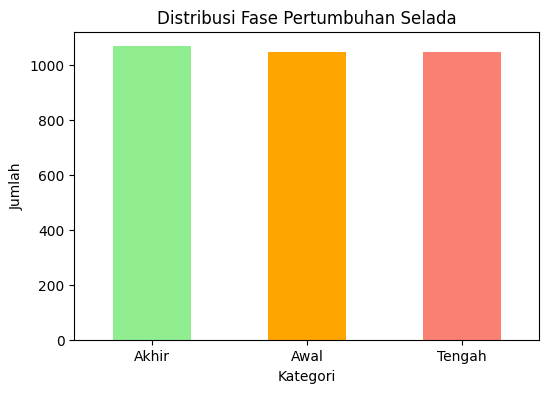

In [23]:
# Verifikasi distribusi data kelas target
class_names = list(le_p2.classes_)

plt.figure(figsize=(6, 4))
df['Kategori_Pertumbuhan'].value_counts().plot(kind='bar', color=['lightgreen', 'orange', 'salmon'])
plt.title('Distribusi Fase Pertumbuhan Selada')
plt.xlabel('Kategori')
plt.ylabel('Jumlah')
plt.xticks(rotation=0)
plt.show()

# Langkah 4 - Buat Model CNN


## Langkah 4.1. - Buat Layer Konvolusi



In [24]:
# Membuat model Neural Network (ANN) yang lebih dalam untuk Praktikum 2
model_p2 = Sequential()
model_p2.add(Dense(64, activation='relu', input_shape=(X_train_p2.shape[1],)))
model_p2.add(BatchNormalization())
model_p2.add(Dense(64, activation='relu'))
model_p2.add(Dropout(0.3))
model_p2.add(Dense(32, activation='relu'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


## Langkah 4.2. - Cek Arsitektur Konvolusi



In [25]:
# Memeriksa Arsitektur Model
model_p2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 64)             │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         2,080 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,816 (26.62 KB)

 Trainable params: 6,688 (26.12 KB)

 Non-trainable params: 128 (512.00 B)

## Langkah 4.3. - Tambahkan Layer Fully Connected



In [26]:
# Menambahkan output layer dengan 3 kelas menggunakan fungsi aktivasi Softmax
model_p2.add(Dense(3, activation='softmax'))

## Langkah 4.4. - Cek Arsitektur Model CNN



In [27]:
# Memeriksa kembali arsitektur model final
model_p2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 64)             │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,915 (27.01 KB)

 Trainable params: 6,787 (26.51 KB)

 Non-trainable params: 128 (512.00 B)

# Langkah 4.5. - Compile Model CNN



In [28]:
# Compile Model
model_p2.compile(optimizer='adam',
                 loss='categorical_crossentropy',
                 metrics=['accuracy'])

# Langkah 5 - Fit Model



In [29]:
# Melatih Model selama 30 epoch
history_p2 = model_p2.fit(X_train_p2, y_train_p2, epochs=30,
                          validation_data=(X_test_p2, y_test_p2), batch_size=16)

Epoch 1/30
159/159 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.3239 - loss: 1.1687 - val_accuracy: 0.3896 - val_loss: 1.0893
Epoch 2/30
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.3795 - loss: 1.0912 - val_accuracy: 0.4148 - val_loss: 1.0677
Epoch 3/30
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4032 - loss: 1.0736 - val_accuracy: 0.5047 - val_loss: 1.0423
Epoch 4/30
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4627 - loss: 1.0332 - val_accuracy: 0.4890 - val_loss: 1.0170
Epoch 5/30
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4580 - loss: 1.0099 - val_accuracy: 0.5095 - val_loss: 0.9620
Epoch 6/30
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4647 - loss: 0.9930 - val_accuracy: 0.5237 - val_loss: 0.9455
Epoch 7/30
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4769 - loss: 0.9690 - val_accuracy: 0.5252 - val_loss: 0.9305
Epoch 8/30
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4966 - loss: 0.9552 - val_accuracy: 0.

# Langkah 6 - Evaluasi Model



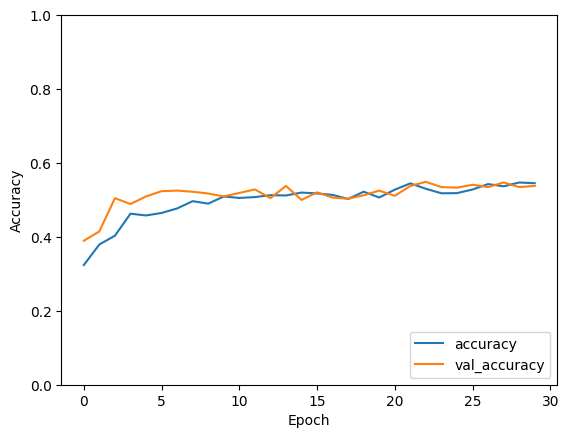

20/20 - 0s - 4ms/step - accuracy: 0.5379 - loss: 0.8298


In [30]:
# Visualisasi Akurasi Pelatihan dan Validasi
plt.plot(history_p2.history['accuracy'], label='accuracy')
plt.plot(history_p2.history['val_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0, 1])
plt.legend(loc='lower right')
plt.show()

test_loss, test_acc = model_p2.evaluate(X_test_p2, y_test_p2, verbose=2)

# Langkah 7 - Cetak Hasil Akurasi



In [31]:
# Mencetak hasil akhir akurasi model
print(f"Akurasi testing pada dataset Lettuce: {test_acc * 100:.2f}%")

Akurasi testing pada dataset Lettuce: 53.79%
